In [9]:
%matplotlib inline

import numpy as np
import soundfile as sf
import matplotlib.pyplot as plt
from scipy.signal import stft, resample_poly
from IPython.display import display, clear_output, Audio
from scipy.signal import butter, sosfiltfilt
import os
import json

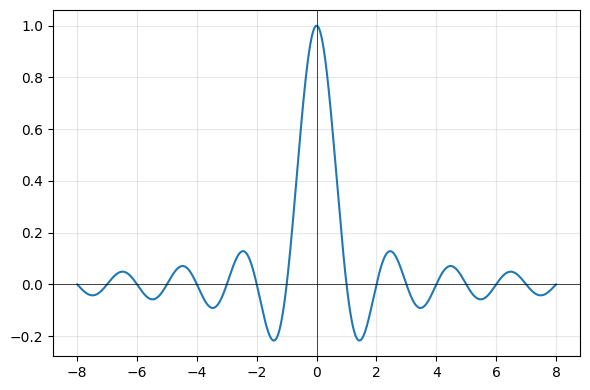

In [10]:
x = np.linspace(-8, 8, 2000)
y = np.sinc(x)

plt.figure(figsize=(6,4))
plt.plot(x, y, label="np.sinc(x)")
plt.axhline(0, color='k', linewidth=0.5)
plt.axvline(0, color='k', linewidth=0.5)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


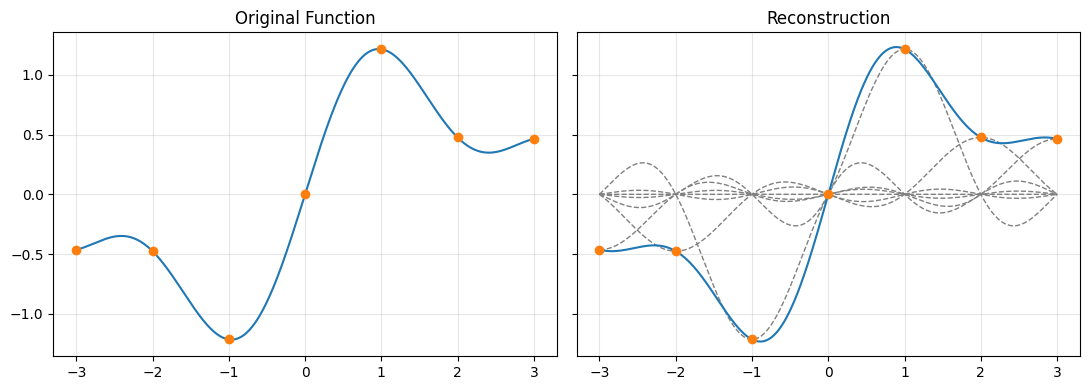

In [11]:
def f(t):
    return np.sin(2*np.pi*0.15*t) + 0.5*np.sin(2*np.pi*0.35*t)

# Continuous-time grid (for "ground truth" and plotting)
t = np.linspace(-3, 3, 4000)
x = f(t)

# Sampling
Ts = 1.0
n = np.arange(np.floor(t.min()/Ts), np.ceil(t.max()/Ts) + 1).astype(int)
t_n = n * Ts
y_n = f(t_n)

# Ideal sinc reconstruction: x_hat(t) = sum y[n] * sinc((t - nTs)/Ts)
tau = (t[:, None] - t_n[None, :]) / Ts                  # shape: (len(t), len(n))
weights = np.sinc(tau)                                  # np.sinc(u) = sin(pi u)/(pi u)
x_hat = (weights * y_n[None, :]).sum(axis=1)

# Plot
fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

# Left: original function and its samples
axs[0].plot(t, x, label='Original f(t)', color='C0')
axs[0].set_title('Original Function')
axs[0].grid(True, alpha=0.3)

# Right: reconstruction via sinc and component sinc terms
for k, tk in enumerate(t_n):
    axs[1].plot(t, y_n[k] * np.sinc((t - tk)/Ts),
                linestyle='--', color='gray', alpha=1, linewidth=1)
axs[1].plot(t, x_hat, color='C0', label='Reconstruction')
axs[1].plot(t_n, y_n, 'o', color='C1', label='Samples')
axs[0].plot(t_n, y_n, 'o', color='C1', label='Samples')
axs[1].set_title('Reconstruction')
axs[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

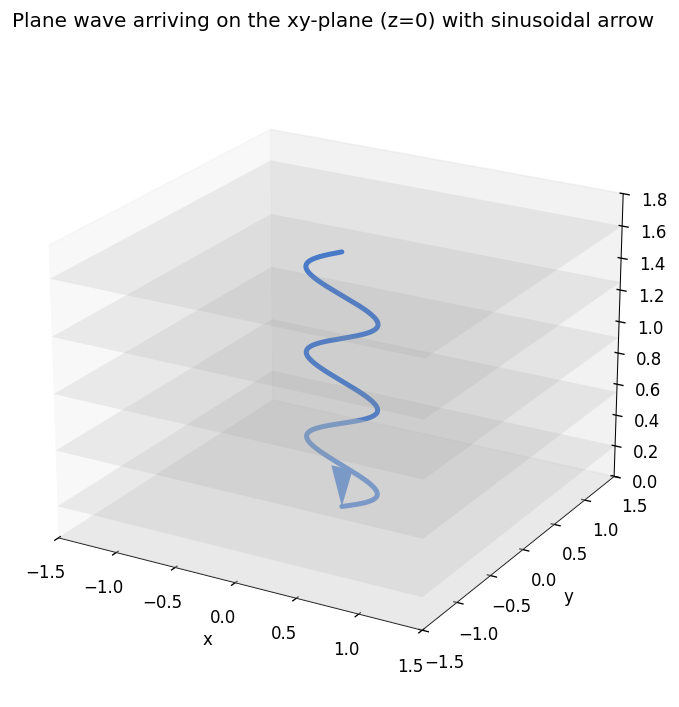

In [12]:
# 3D illustration of a plane wave arriving on the xy-plane
# Requirements: Python 3, numpy, matplotlib
# Install: pip install matplotlib numpy

import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

# -------------------
# Parameters
# -------------------
plane_extent = 1.5          # Half-size of the xy-plane square (range [-extent, extent])
wave_amplitude = 0.3        # Lateral amplitude of the sinusoidal arrow (in x)
z_max = 1.6                 # How far above the plane the arrow starts
cycles = 3                  # Number of sinusoidal cycles along the arrow
arrow_linewidth = 3.0
arrow_color = '#2a6fdb'     # Blue-ish arrow
plane_color = (0.85, 0.85, 0.85, 0.4)  # xy-plane color (RGBA)
wavefront_color = (0.6, 0.6, 0.6, 0.15) # wavefront planes color (RGBA)
num_wavefronts = 5          # How many parallel wavefront planes
arrowhead_width = 0.18      # Width of the arrowhead (x-direction)
arrowhead_length = 0.25     # Length of the arrowhead (z-direction)

# -------------------
# Create figure
# -------------------
fig = plt.figure(figsize=(8, 6), dpi=120)
ax = fig.add_subplot(111, projection='3d')

# -------------------
# Draw the xy-plane (z=0)
# -------------------
X = np.linspace(-plane_extent, plane_extent, 2)
Y = np.linspace(-plane_extent, plane_extent, 2)
XX, YY = np.meshgrid(X, Y)
ZZ = np.zeros_like(XX)
ax.plot_surface(XX, YY, ZZ, color=plane_color, rstride=1, cstride=1, shade=False)

# -------------------
# Draw parallel wavefront planes above xy-plane
# Representing a plane wave approaching along -z
# -------------------
z_fronts = np.linspace(z_max, 0.2, num_wavefronts)
wavefront_quads = []
for zf in z_fronts:
    quad = [
        (-plane_extent, -plane_extent, zf),
        ( plane_extent, -plane_extent, zf),
        ( plane_extent,  plane_extent, zf),
        (-plane_extent,  plane_extent, zf),
    ]
    wavefront_quads.append(quad)

wf = Poly3DCollection(wavefront_quads, facecolors=[wavefront_color]*len(z_fronts),
                      edgecolors='none')
ax.add_collection3d(wf)

# -------------------
# Draw a sine-wave-shaped arrow indicating direction of arrival
# We parametrize along z, from z_max down to 0 (approaching the xy-plane).
# x(z) = A * sin(k z), y = 0, z in [z_max -> 0]
# -------------------
z_vals = np.linspace(z_max, 0.0, 400)
k = cycles * 2 * np.pi / z_max  # set waveform cycles along z
x_vals = wave_amplitude * np.sin(k * z_vals)
y_vals = np.zeros_like(z_vals)

# Plot the sinusoidal path
ax.plot(x_vals, y_vals, z_vals, color=arrow_color, linewidth=arrow_linewidth, solid_capstyle='round')

# Add a simple triangular arrowhead at the endpoint near the plane (y=0, z=0)
# Triangle lies in the x-z plane and points toward decreasing z (into the plane).
x_tip = x_vals[-1]
z_tip = 0.0
y_tip = 0.0

arrowhead = [
    (x_tip,               y_tip, z_tip),  # tip (on plane)
    (x_tip - arrowhead_width/2, y_tip, z_tip + arrowhead_length),
    (x_tip + arrowhead_width/2, y_tip, z_tip + arrowhead_length),
]
arrowhead_poly = Poly3DCollection([arrowhead], facecolors=arrow_color, edgecolors='none')
ax.add_collection3d(arrowhead_poly)

# -------------------
# Axes formatting
# -------------------
ax.set_xlim(-plane_extent, plane_extent)
ax.set_ylim(-plane_extent, plane_extent)
ax.set_zlim(0, z_max + 0.2)

ax.set_xlabel('x')
ax.set_ylabel('y')
ax.set_zlabel('z')

# Make view a bit nicer
ax.view_init(elev=22, azim=-60)
ax.grid(False)

# Subtle axis pane/lines
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    axis.line.set_linewidth(0.6)

# Title
ax.set_title('Plane wave arriving on the xy-plane (z=0) with sinusoidal arrow', pad=16)

plt.tight_layout()
plt.show()


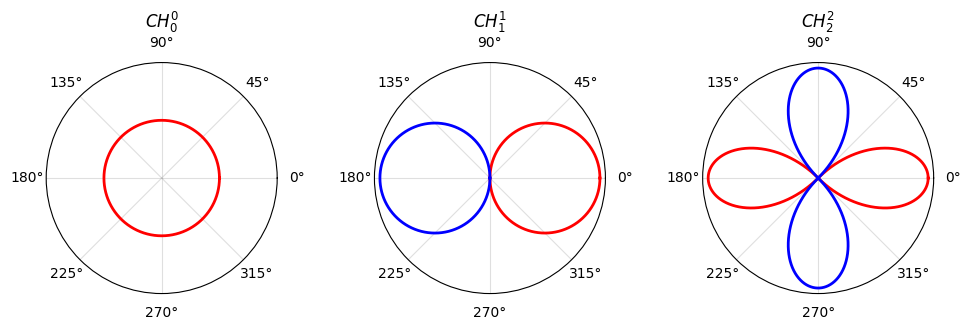

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
ms = [0, 1, 2]
theta = np.linspace(0, 2*np.pi, 4001)  # dense for smooth zero-crossings

fig = plt.figure(figsize=(12, 3))


for m in range(3):
    for s in range(0, 1):
        if m==0 and s == 1:
            continue
        r = np.cos(m * theta + s * np.pi/2)
        ax = fig.add_subplot(1, 3, 3*s + m+1, projection='polar')

        # Mask by sign for color-coding
        r_pos = np.ma.masked_less(r, 0)          # >= 0 -> red
        r_neg = np.ma.masked_greater_equal(r, 0) # < 0  -> blue

        ax.plot(theta, np.abs(r_pos), color='red',  lw=2)
        ax.plot(theta, np.abs(r_neg), color='blue', lw=2)

        ax.grid(True, alpha=0.4)
        ax.set_rticks([])  # declutter radial ticks
        ax.set_title(f"$CH_{{{m}}}^{{{m}}}$")

# Optional overall title
# plt.tight_layout()
plt.show()


<>:27: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
<>:27: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
/var/folders/l0/9fzt8fvj0zqdh211mn6mc0000000gp/T/ipykernel_2656/252637412.py:27: SyntaxWarning: "\$" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\$"? A raw string is also an option.
  ax.set_title(f"$\\text\$")


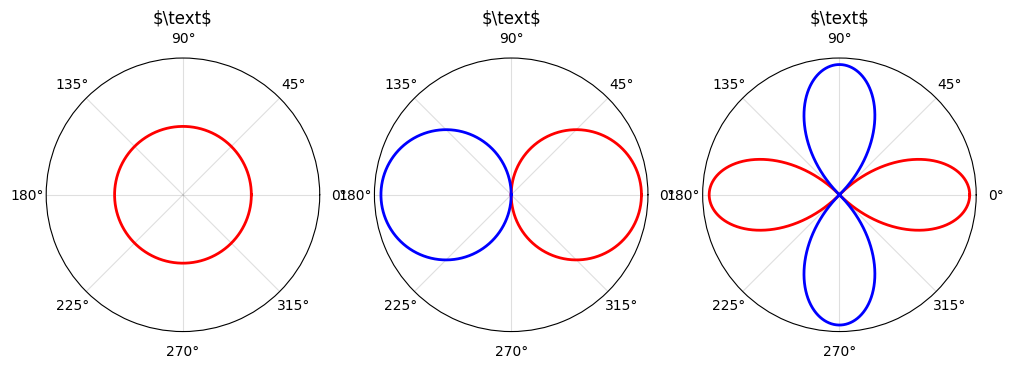

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Parameters
ms = [0, 1, 2]
theta = np.linspace(0, 2*np.pi, 4001)  # dense for smooth zero-crossings

fig = plt.figure(figsize=(12, 4))


for m in range(3):
    for s in range(0, 1):
        if m==0 and s == 1:
            continue
        r = np.cos(m * theta + s * np.pi/2)
        ax = fig.add_subplot(1, 3, 3*s + m+1, projection='polar')

        # Mask by sign for color-coding
        r_pos = np.ma.masked_less(r, 0)          # >= 0 -> red
        r_neg = np.ma.masked_greater_equal(r, 0) # < 0  -> blue

        ax.plot(theta, np.abs(r_pos), color='red',  lw=2)
        ax.plot(theta, np.abs(r_neg), color='blue', lw=2)

        ax.grid(True, alpha=0.4)
        ax.set_rticks([])  # declutter radial ticks
        ax.set_title(f"$\\text\$")

# Optional overall title
# plt.tight_layout()
plt.show()

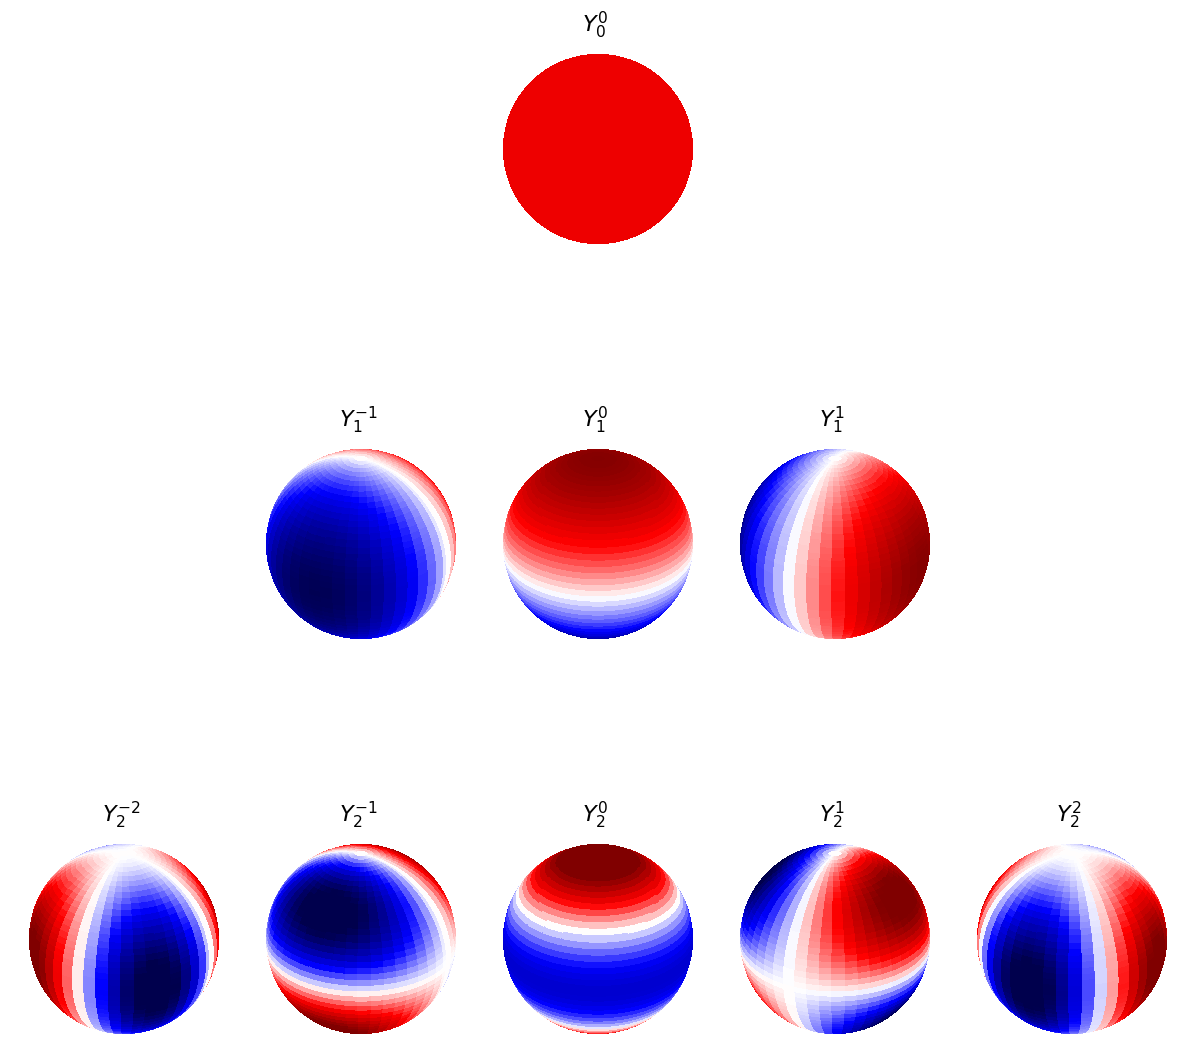

In [5]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cm, colors
from scipy.special import lpmv, factorial, legendre

N = 100

def sph_harm(n, m, azi, zeni):

    azi = np.array(azi).flatten()
    zeni = np.array(zeni).flatten()
    
    if azi.ndim != zeni.ndim:
        raise ValueError('azi and ele must be of the same dimension')
    
    mabs = np.abs(m)
    
    # Azimuthal part

    azi_part = 1
    if m < 0:
        azi_part = np.sqrt(2)*np.sin(mabs*azi)
    elif m > 0:
        azi_part = np.sqrt(2)*np.cos(mabs*azi)
    
    # Zenithal part (associated Legendre polynomials) - remember to choose which convention to use regarding the Condon-Shortley phase
    zeni_part = lpmv(mabs, n, np.cos(zeni)) * ((-1.0)**mabs)

    # Normalization term
    norm_part = np.sqrt((2*n+1)/(4*np.pi)*factorial(n-mabs)/factorial(n+mabs))
    
    return (azi_part*zeni_part*norm_part).reshape((N, N))

# Max degree
Lmax = 2

# Angular grid
theta = np.linspace(0, np.pi, N)      # polar angle
phi = np.linspace(0, 2 * np.pi, N)    # azimuthal angle
theta, phi = np.meshgrid(theta, phi)

# Figure
fig = plt.figure(figsize=(12, 12))
nrows = Lmax + 1
ncols = 2 * Lmax + 1

# Colormap normalization for signed real part
norm = colors.Normalize(vmin=-0.5, vmax=0.5)

for l in range(Lmax + 1):
    for m in range(-l, l + 1):
        # Place each (l,m) in a centered pyramid layout
        col = m + Lmax + 1
        row = l + 1
        ax = fig.add_subplot(nrows, ncols, (row - 1) * ncols + col, projection='3d')

        # Complex spherical harmonic Y_l^m(phi, theta)
        Y = sph_harm(l, m, phi, theta)

        # Use the real part for visualization
        R = np.real(Y)

        # Radius = magnitude of the real part
        r = np.abs(R)

        # Spherical -> Cartesian
        x = np.sin(theta) * np.cos(phi)
        y = np.sin(theta) * np.sin(phi)
        z = np.cos(theta)

        # Color by signed value
        facecolors = cm.seismic(norm(R))

        ax.plot_surface(
            x, y, z,
            rstride=2, cstride=2,
            facecolors=facecolors,
            linewidth=0, antialiased=False, shade=False
        )

        ax.set_title(f"$Y_{{{l}}}^{{{m}}}$", pad=2, fontsize=16)
        ax.set_axis_off()
        ax.set_box_aspect((1, 1, 1))

        # Consistent axis limits
        lim = 0.7
        ax.set_xlim(-lim, lim)
        ax.set_ylim(-lim, lim)
        ax.set_zlim(-lim, lim)

plt.tight_layout()
plt.show()
